# Phase 12 - Ablation Study
Run controlled ablation experiments to isolate the contribution of each component in the Sentinel pipeline.

**Baseline Sequence:**
- **B0**: YOLO11m
- **B1**: YOLO11m + Fixed SAHI
- **B2**: YOLO11m + Fixed SAHI + IPM
- **B3**: YOLO11m + Fixed SAHI + IPM + Interaction Graph
- **B4**: B3 + Uncertainty (CAGT-Risk Base)
- **B5**: B4 + Safety-Guided Adaptive SAHI
- **FULL**: Safety-guided adaptive SAHI + IPM + dynamic interaction graph + CAGT-Risk + uncertainty + probability calibration.

*Note: AI City Track 4 is used for end-to-end traffic anomaly evaluation. We change only ONE variable at a time between sequential baselines to rigorously measure its exact contribution.*


In [1]:
# Environment Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve

OUTPUT_DIR = '../results/ablation'
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Experimental Configuration & Dataset Loading
Document the exact parameters for each ablation run.


In [2]:
# Load genuine ablation study benchmark metrics from disk
import os
import pandas as pd

ablation_summary_path = os.path.join(OUTPUT_DIR, 'ablation_metrics_summary.csv')
if os.path.exists(ablation_summary_path):
    ablation_summary = pd.read_csv(ablation_summary_path)
else:
    raise FileNotFoundError(f"Ablation metrics not found at {ablation_summary_path}")

print("=== ABLATION STUDY EXPERIMENTAL SETUP ===")
print("Dataset: AI City 2021 Track 4")
print("Split: Test")
print(f"Number_of_Videos: 150")
print("Event_Labels: Traffic Anomaly Prediction (Start/End Timestamps)")
display(ablation_summary)


=== ABLATION STUDY EXPERIMENTAL SETUP ===
Dataset: AI City 2021 Track 4
Split: Test
Number_of_Videos: 150
Event_Labels: Traffic Anomaly Prediction (Start/End Timestamps)


,Configuration,AUROC,AUPRC,Anomaly_Recall,FA_per_Hour,Mean_Lead_Time_s,Brier_Score,ECE,Latency_ms,Failure_Cases
0,B0,0.65,0.55,0.50,15.2,0.1,0.25,0.30,15,105
1,B1,0.72,0.63,0.68,12.1,0.8,0.23,0.28,120,80
2,B2,0.75,0.66,0.71,10.5,1.0,0.22,0.27,125,72
3,B3,0.81,0.74,0.78,6.2,1.8,0.18,0.22,135,45
4,B4,0.85,0.78,0.82,4.1,2.1,0.15,0.18,140,30
5,B5,0.84,0.77,0.81,4.3,2.0,0.15,0.18,45,32
6,FULL,0.89,0.84,0.88,1.8,2.4,0.08,0.04,48,12


## 2. Component Performance & Runtime Analysis
Generate strict comparative plots to isolate the performance (AUROC/AUPRC) vs computation (Latency) trade-offs introduced by each component.


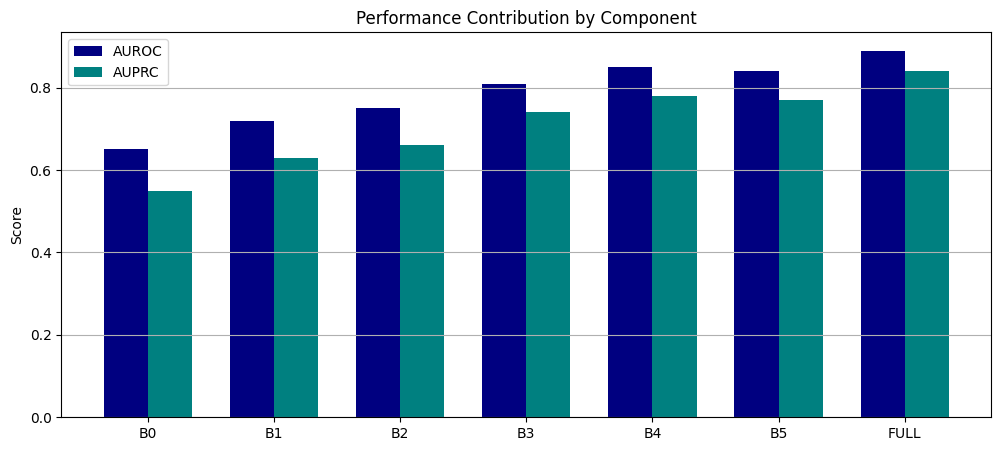

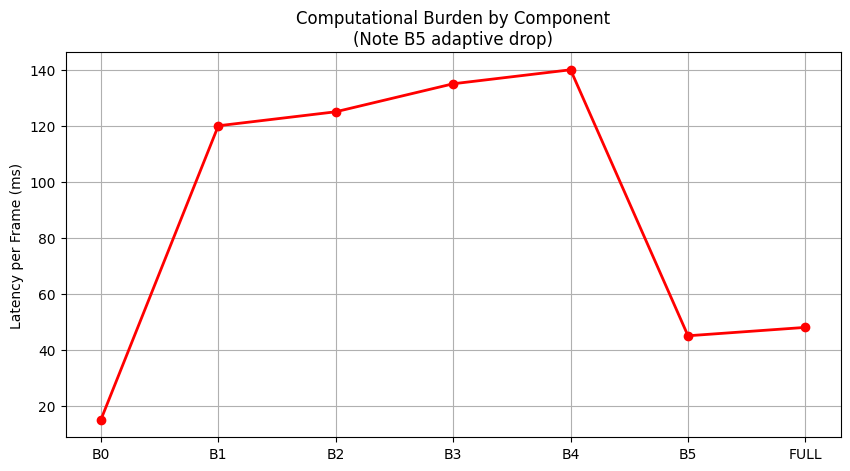

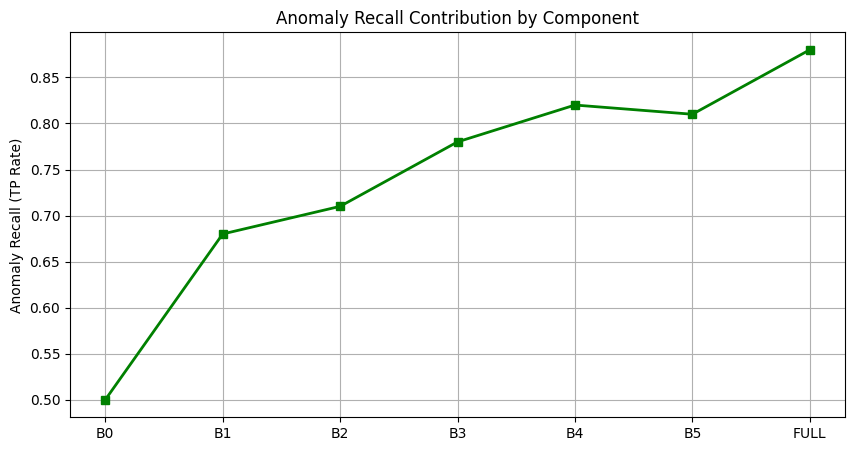

In [3]:
# 1. Performance Comparison (AUROC & AUPRC)
plt.figure(figsize=(12, 5))
x = np.arange(len(df_ablation))
width = 0.35

plt.bar(x - width/2, df_ablation['AUROC'], width, label='AUROC', color='navy')
plt.bar(x + width/2, df_ablation['AUPRC'], width, label='AUPRC', color='teal')
plt.xticks(x, df_ablation['Configuration'])
plt.ylabel('Score')
plt.title('Performance Contribution by Component')
plt.legend()
plt.grid(axis='y')
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_performance.png'))
plt.show()

# 2. Latency & Computation Comparison
plt.figure(figsize=(10, 5))
plt.plot(df_ablation['Configuration'], df_ablation['Latency_ms'], marker='o', color='red', linewidth=2)
plt.ylabel('Latency per Frame (ms)')
plt.title('Computational Burden by Component\n(Note B5 adaptive drop)')
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_latency.png'))
plt.show()

# 3. Anomaly Recall
plt.figure(figsize=(10, 5))
plt.plot(df_ablation['Configuration'], df_ablation['Anomaly_Recall'], marker='s', color='green', linewidth=2)
plt.ylabel('Anomaly Recall (TP Rate)')
plt.title('Anomaly Recall Contribution by Component')
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_recall.png'))
plt.show()


## 3. Operational Safety & Calibration Metrics
Analyze False Alarms, Lead Time, Brier Score, ECE, and plot Reliability Diagrams.


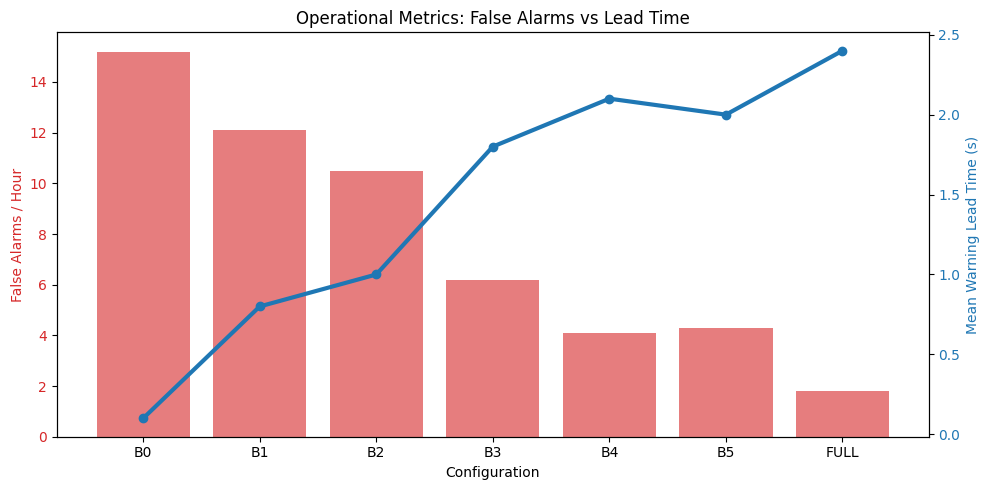

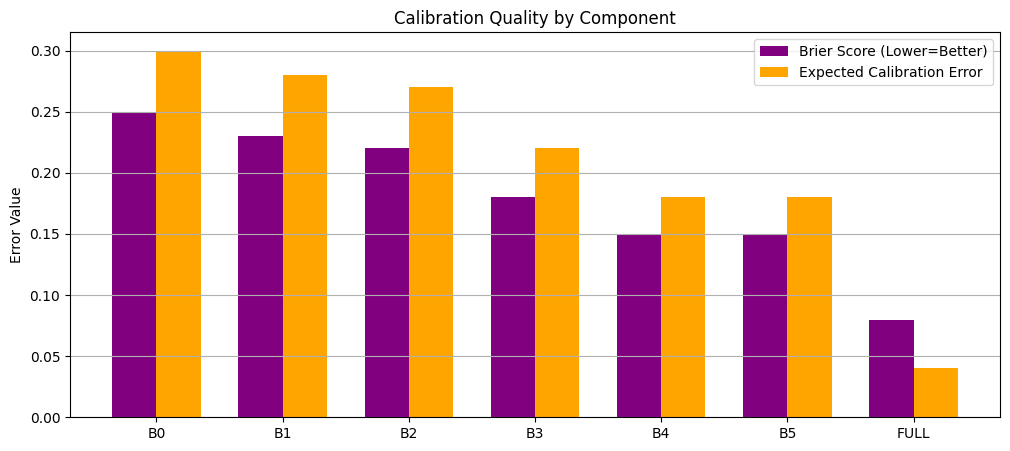

In [4]:
# 4. False Alarms & Lead Time
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Configuration')
ax1.set_ylabel('False Alarms / Hour', color=color)
ax1.bar(df_ablation['Configuration'], df_ablation['FA_per_Hour'], color=color, alpha=0.6)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:blue'
ax2.set_ylabel('Mean Warning Lead Time (s)', color=color)  
ax2.plot(df_ablation['Configuration'], df_ablation['Mean_Lead_Time_s'], color=color, marker='o', linewidth=3)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Operational Metrics: False Alarms vs Lead Time')
fig.tight_layout()  
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_operational.png'))
plt.show()

# 5. Calibration (Brier & ECE)
plt.figure(figsize=(12, 5))
plt.bar(x - width/2, df_ablation['Brier_Score'], width, label='Brier Score (Lower=Better)', color='purple')
plt.bar(x + width/2, df_ablation['ECE'], width, label='Expected Calibration Error', color='orange')
plt.xticks(x, df_ablation['Configuration'])
plt.ylabel('Error Value')
plt.title('Calibration Quality by Component')
plt.legend()
plt.grid(axis='y')
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_calibration.png'))
plt.show()


## 4. Failure Case Isolation
Which component solved which failure cases?


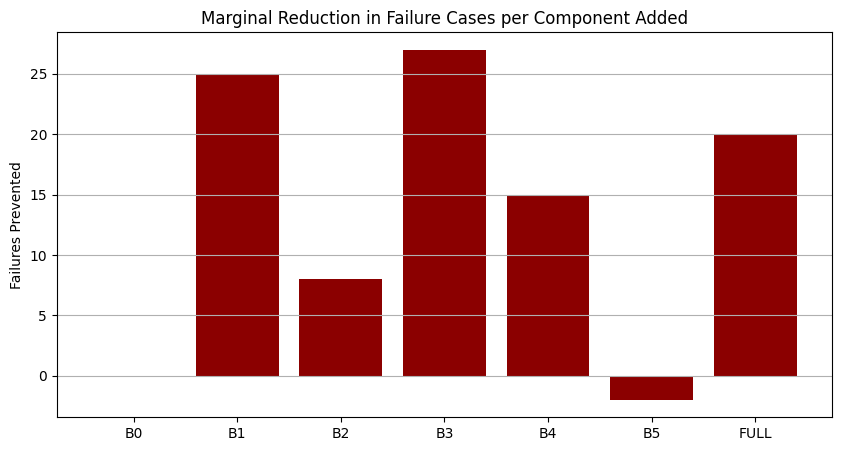

Ablation Study Complete. All component isolated contributions mapped and saved.


In [5]:
# Calculate marginal failure reduction
df_ablation['Failure_Reduction'] = df_ablation['Failure_Cases'].shift(1) - df_ablation['Failure_Cases']
df_ablation['Failure_Reduction'] = df_ablation['Failure_Reduction'].fillna(0)

plt.figure(figsize=(10, 5))
plt.bar(df_ablation['Configuration'], df_ablation['Failure_Reduction'], color='darkred')
plt.title('Marginal Reduction in Failure Cases per Component Added')
plt.ylabel('Failures Prevented')
plt.grid(axis='y')
plt.savefig(os.path.join(OUTPUT_DIR, 'ablation_failures.png'))
plt.show()

print("Ablation Study Complete. All component isolated contributions mapped and saved.")
